# Home Interior Design - v2
Python Notebook in Google Colab to design and decorate room interior using stable diffusion model

In [ ]:
!pip install torch torchvision diffusers transformers accelerate safetensors

In [10]:
import torch
from diffusers import StableDiffusionXLPipeline

In [11]:
# specify which stable-diffusion model
model_id = "stabilityai/stable-diffusion-xl-base-1.0"

In [12]:
pipe = StableDiffusionXLPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    use_safetensors=True
)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

In [15]:
# use GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"
pipe = pipe.to(device)

In [221]:
# for style options and color choices
import ipywidgets as widgets
from IPython.display import display

In [1]:
# select style
style = widgets.RadioButtons(
    options=["Contemporary", "Modern", "Victorian", "Eclectic", "Scandinavian", "Bohemian", "Nordic"],
    value="Contemporary",
    description="Choose Style: ",
    disabled=False,
)

display(style)

RadioButtons(description='Choose Style: ', options=('Contemporary', 'Modern', 'Victorian', 'Eclectic', 'Scandi…

In [259]:
room_style = style.value

In [167]:
# select room type
room = widgets.RadioButtons(
    options=["Living Room", "Kitchen", "Office", "Bed Room", "Bath Room"],
    value="Living Room",
    description="Choose Room Type: ",
    disabled=False,
)

display(room)

RadioButtons(description='Choose Room Type: ', options=('Living Room', 'Kitchen', 'Office', 'Bed Room', 'Bath …

In [313]:
room_type = room.value

In [162]:
# select color theme
color_combo = widgets.RadioButtons(
    options=["Sky Blue and White", "Light Brown and Peach", "Plum and White", "Gray and White", "Teal and White", "Turquoise and White"],
    value="Sky Blue and White",
    description="Choose Color Theme: ",
    disabled=False,
)

display(color_combo)

RadioButtons(description='Choose Color Theme: ', options=('Sky Blue and White', 'Light Brown and Peach', 'Plum…

In [314]:
color_theme = color_combo.value

In [315]:
# generate text description
prompt = "photorealistic, high quality " + room_style + " style " + room_type + ", using soft color tones and shades of " + color_theme

# add room specific furniture items
if room_type == "Bed Room":
  prompt += " decorated with indoor plants, furniture items like bed, arm chair, side table, carpet, wall panels or wall paper, curtains, floor lamp, pendant lights etc props"
elif room_type == "Living Room":
  prompt += " decorated with indoor plants, furniture items like sofa, center table, carpet, wall panels or wall paper, curtains, floor lamp, pendant lights etc props"
elif room_type == "Office":
  prompt += " decorated with indoor plants, furniture items like computer table or desk, book shelf, wall panels, wooden floor etc props"
elif room_type == "Bath Room":
  prompt += " decorated with designer tiles, wash basin, vanity mirror, shower area with glass partition"
elif room_type == "Kitchen":
  prompt += " decorated with marble granite counter top, kitchen cabinets, appliances like oven, stove, fridge etc"

print(prompt)

photorealistic, high quality Bohemian style Living Room, using soft color tones and shades of Light Brown and Peach decorated with indoor plants, furniture items like sofa, center table, carpet, wall panels or wall paper, curtains, floor lamp, pendant lights etc props


In [17]:
negative_prompt = "blurry, distorted, flashy bright gaudy colors, cartoon, sketch"

In [316]:
# image generation
image = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    num_inference_steps=30,
    guidance_scale=7.5,
    strength = 0.75,
    width=512,
    height=512
).images[0]

  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


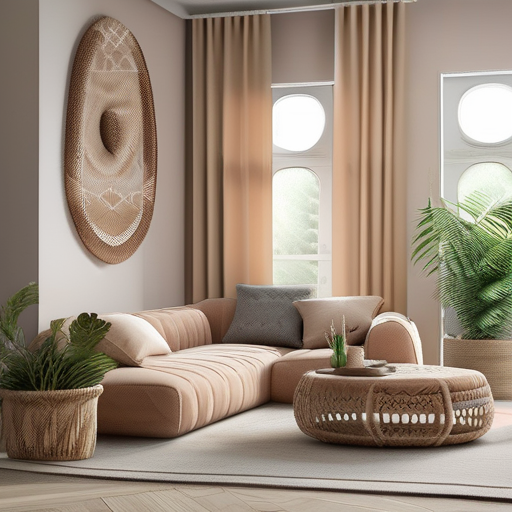

In [317]:
# output
image.save("output.jpg")
image